In [22]:
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Chargement du dataset
df = pd.read_csv("Statedata_test.csv")

# 2. Suppression des colonnes non désirées et de l'ID
colonnes_a_supprimer = [
    "Astronaut_ID",
    "Sociability",
    "Suspect_Behavior",
    "Adaptability",
    "Pet_the_Robot_Cat",
]
df_clean = df.drop(
    columns=[col for col in colonnes_a_supprimer if col in df.columns]
)

# 3. Réduction du dataset à 4000 lignes (échantillonnage aléatoire)
n_cible = 1000
if len(df_clean) > n_cible:
  df_clean = df_clean.sample(n=n_cible, random_state=42)
  print(f"Dataset réduit à {n_cible} lignes.")
else:
  print(
      f"Le dataset contient déjà moins de {n_cible} lignes ({len(df_clean)}"
      " lignes)."
  )

print("Dimensions finales du dataset :", df_clean.shape)
print("Colonnes conservées :", df_clean.columns.tolist())
df_clean.head()

Dataset réduit à 1000 lignes.
Dimensions finales du dataset : (1000, 9)
Colonnes conservées : ['Stress_Level', 'Happiness', 'Mood_Score', 'Depression', 'Sleep_Quality', 'Workload Perception', 'Time_Perception', 'Food', 'Communication_with_Earth_mins']


,Stress_Level,Happiness,Mood_Score,Depression,Sleep_Quality,Workload Perception,Time_Perception,Food,Communication_with_Earth_mins
35221,Medium,7,Positive,31.691629,6.45,Impossible,Normal,Bad,1.72
12640,Low,5,Neutral,89.919326,0.87,Possible,Fast,Good,5.63
53656,Low,5,Neutral,80.276862,1.17,Easy,Fast,Good,4.14
1165,Medium,6,Neutral,105.808435,0.28,Impossible,Slow,Neutral,0.34
68981,Low,7,Positive,66.334721,3.14,Impossible,Slow,Neutral,0.85


In [23]:
target_column = "Depression"
X = df_clean.drop(columns=[target_column])
y = df_clean[target_column]

# Identification des types de colonnes (numériques vs catégorielles)
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Pipelines de prétraitement automatique
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

# Pipeline complet avec Random Forest Regressor
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
        ),
    ]
)

# Séparation Train / Test (80% / 20%) et Entraînement
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Entraînement du modèle en cours...")
model_pipeline.fit(X_train, y_train)
print("Entraînement terminé avec succès !")

C:\Users\LGI\AppData\Local\Temp\ipykernel_14188\1491319505.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


Entraînement du modèle en cours...
Entraînement terminé avec succès !


In [24]:
y_pred = model_pipeline.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Erreur absolue moyenne (MAE) : {mae:.2f} points")
print(f"Score R² (variance expliquée) : {r2:.4f}")

# Sauvegarde du modèle pour l'équipe Backend / Intégration
model_filename = "mental_stress_model.pkl"
joblib.dump(model_pipeline, model_filename)
print(f"Modèle sauvegardé sous : {model_filename}")

Erreur absolue moyenne (MAE) : 3.83 points
Score R² (variance expliquée) : 0.9772
Modèle sauvegardé sous : mental_stress_model.pkl


In [25]:

import joblib
import pandas as pd
import pprint

# 1. Simulation des réponses envoyées par l'interface
reponses_test = {
    "Stress_Level": "High",               # 'Low', 'Medium', 'High'
    "Happiness": 3,                       # 0 à 9
    "Mood_Score": "Negative",             # 'Positive', 'Neutral', 'Negative'
    "Sleep_Quality": 3.46,                # 0.0 à 62.53
    "Workload Perception": "Impossible",    # 'Impossible', 'Possible', 'Easy'
    "Time_Perception": "Slow",            # 'Slow', 'Normal', 'Fast'
    "Food": "Bad",                        # 'Bad', 'Neutral', 'Good'
    "Communication_with_Earth_mins": 2.0  
}

# 2. Fonction d'évaluation avec des textes plus chaleureux et personnalisés
def evaluer_etat_psychologique(reponses_astronaute: dict) -> dict:
    model = joblib.load("mental_stress_model.pkl")
    
    categories = {}
    
    # Analyse du stress
    stress = reponses_astronaute.get("Stress_Level", "Medium")
    categories["stress"] = {
        "Low": "Optimal",
        "Medium": "Vigilance",
        "High": "Critique"
    }.get(stress, "Vigilance")
    
    # Analyse du bonheur
    happiness = reponses_astronaute.get("Happiness", 5)
    if happiness >= 7:
        categories["bien_etre"] = "Optimal"
    elif happiness >= 3:
        categories["bien_etre"] = "Vigilance"
    else:
        categories["bien_etre"] = "Critique"
        
    # Analyse du sommeil
    sommeil_val = reponses_astronaute.get("Sleep_Quality", 4.98)
    if sommeil_val >= 6.92:
        categories["sommeil"] = "Optimal"
    elif sommeil_val >= 1.43:
        categories["sommeil"] = "Vigilance"
    else:
        categories["sommeil"] = "Critique"

    # Prédiction du score de dépression par le modèle ML
    df_input = pd.DataFrame([reponses_astronaute])
    score_depression_predit = float(model.predict(df_input)[0])
    
    # Évaluation textuelle plus humaine de l'état global
    if score_depression_predit < 35:
        etat_global = "Tout va bien, tu gères ta mission avec brio !"
    elif score_depression_predit < 75:
        etat_global = "Attention, la fatigue et la pression commencent à s'accumuler."
    else:
        etat_global = "Alerte rouge : tu montres des signes importants de surcharge émotionnelle."

    # Génération de recommandations bienveillantes et ciblées
    conseils = []
    if categories["stress"] == "Critique":
        conseils.append("Prends quelques minutes pour respirer profondément et lève le pied sur le planning aujourd'hui.")
    if categories["sommeil"] == "Critique":
        conseils.append("Ton corps réclame du repos. Essaie d'aménager une plage de sommeil supplémentaire et tamise ta cabine.")
    if categories["bien_etre"] == "Critique" or score_depression_predit >= 75:
        conseils.append("Il est fortement conseillé de planifier un appel sécurisé avec tes proches ou l'équipe de soutien sur Terre.")
        
    if not conseils:
        conseils.append("Tes indicateurs sont au beau fixe. Continue à prendre soin de toi et de ta routine !")

    return {
        "diagnostic_global": etat_global,
        "score_de_vulnerabilite": round(score_depression_predit, 2),
        "analyse_par_indicateur": categories,
        "conseils_personnalises": conseils
    }

# 3. Exécution du test dans le notebook
resultat = evaluer_etat_psychologique(reponses_test)
pprint.pprint(resultat)

{'analyse_par_indicateur': {'bien_etre': 'Vigilance',
                            'sommeil': 'Vigilance',
                            'stress': 'Critique'},
 'conseils_personnalises': ['Prends quelques minutes pour respirer '
                            'profondément et lève le pied sur le planning '
                            "aujourd'hui."],
 'diagnostic_global': 'Attention, la fatigue et la pression commencent à '
                      "s'accumuler.",
 'score_de_vulnerabilite': 62.68}


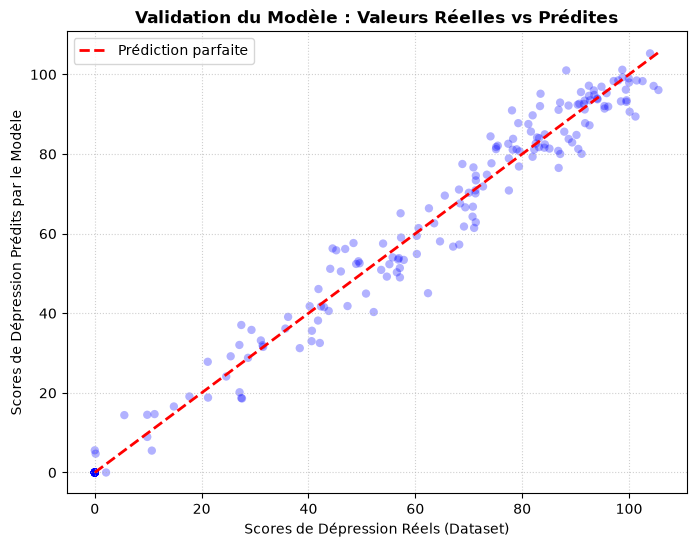

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Récupération des prédictions sur le jeu de test
y_pred_test = model_pipeline.predict(X_test)

# Création du graphique
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_test, alpha=0.3, color="blue", edgecolors="none")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
    label="Prédiction parfaite",
)

plt.xlabel("Scores de Dépression Réels (Dataset)")
plt.ylabel("Scores de Dépression Prédits par le Modèle")
plt.title(
    "Validation du Modèle : Valeurs Réelles vs Prédites",
    fontsize=12,
    fontweight="bold",
)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [ ]:
valeur_max=df["Communication_with_Earth_mins"].max()
valeur_min=df["Communication_with_Earth_mins"].min()

print(f"la valeur maximale de Communication_with_Earth_mins est : {valeur_max}")
print(f"la valeur minimale de Communication_with_Earth_mins est : {valeur_min}")

In [27]:
valeur_max=df["Communication_with_Earth_mins"].max()
valeur_min=df["Communication_with_Earth_mins"].min()

print(f"la valeur maximale de Communication_with_Earth_mins est : {valeur_max}")
print(f"la valeur minimale de Communication_with_Earth_mins est : {valeur_min}")

la valeur maximale de Communication_with_Earth_mins est : 54.73
la valeur minimale de Communication_with_Earth_mins est : 0.0
